# CS6886W Assignment 1 — Driver Notebook (`driver.ipynb`)
## Exploring VGG6 on CIFAR-10 in TensorFlow & Google Colab

- **GitHub Repository**: [https://github.com/Rakesh4ever/iitm-cs6886w-vgg6-cifar10](https://github.com/Rakesh4ever/iitm-cs6886w-vgg6-cifar10)
- **Purpose**: This `driver.ipynb` notebook acts as the interactive launcher for Google Colab (either in the browser or via the VS Code Google Colab extension). It clones the modular `src/*.py` package onto the Colab GPU runtime and executes training (`src/train.py`), visualization (`outputs/baseline_curves.png`), standalone evaluation (`src/evaluate.py`), and W&B hyperparameter sweeps (`src/sweep.py`).

**Instructions for Evaluators / TAs**:
1. Select a **GPU Runtime** (`Runtime -> Change runtime type -> T4 GPU` in Colab, or `Select Kernel -> Colab -> GPU` in VS Code).
2. Run **Steps 1 through 6** sequentially.

In [6]:
# ==============================================================================
# STEP 1: CLONE THE MODULAR .py PROJECT FROM GITHUB INTO THE COLAB GPU SERVER
# ==============================================================================
# Purpose of imports:
#   - os: Navigate directories cleanly on Google Colab or local machine
#   - tensorflow: Verify TensorFlow version and confirm T4 GPU hardware availability
import os

if os.path.exists("/content"):
    os.chdir("/content")
    !rm -rf /content/iitm-cs6886w-vgg6-cifar10
    !git clone https://github.com/Rakesh4ever/iitm-cs6886w-vgg6-cifar10.git
    os.chdir("/content/iitm-cs6886w-vgg6-cifar10")

print("Current Working Directory:", os.getcwd())

# Install required dependencies
!pip install -q -r requirements.txt

# Verify modular Python files inside src/
!ls -la src/

import tensorflow as tf
print("TensorFlow Version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

Cloning into 'iitm-cs6886w-vgg6-cifar10'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 39 (delta 13), reused 35 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 290.14 KiB | 1.58 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Current Working Directory: /content/iitm-cs6886w-vgg6-cifar10
total 68
drwxr-xr-x 2 root root  4096 Oct 27 12:28 .
drwxr-xr-x 4 root root  4096 Oct 27 12:28 ..
-rw-r--r-- 1 root root  8770 Oct 27 12:28 dataset.py
-rw-r--r-- 1 root root  6463 Oct 27 12:28 evaluate.py
-rw-r--r-- 1 root root   268 Oct 27 12:28 __init__.py
-rw-r--r-- 1 root root  8707 Oct 27 12:28 model.py
-rw-r--r-- 1 root root  4781 Oct 27 12:28 sweep.py
-rw-r--r-- 1 root root 14561 Oct 27 12:28 train.py
TensorFlow Version: 2.21.0
Available GPUs: []


In [7]:
# ==============================================================================
# STEP 2: LOGIN TO WEIGHTS & BIASES (W&B) [OPTIONAL FOR LOCAL RUNS]
# ==============================================================================
# Purpose of imports:
#   - os: Set WANDB_API_KEY environment variable for child training processes
#   - wandb: Authenticate session with https://api.wandb.ai
import os
import wandb

# Paste your 40-character W&B API key from https://wandb.ai/authorize below:
WANDB_KEY = os.environ.get("WANDB_API_KEY", "YOUR_WANDB_API_KEY")

if WANDB_KEY != "YOUR_WANDB_API_KEY" and len(WANDB_KEY.strip()) >= 32:
    os.environ["WANDB_API_KEY"] = WANDB_KEY.strip()
    wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
else:
    print("W&B API Key not set. Training in Step 3 will run locally and still generate all plots and checkpoints.")

W&B API Key not set. Training in Step 3 will run locally and still generate all plots and checkpoints.


In [10]:
# ==============================================================================
# STEP 3: TRAIN VGG6 WITH BEST CONFIGURATION (src/train.py)
# ==============================================================================
# Executes modular training pipeline (src/train.py -> src/dataset.py, src/model.py, src/evaluate.py)
# Saves:
#   - Best model checkpoint : checkpoints/best_vgg6_cifar10.keras
#   - Loss & Accuracy plot  : outputs/baseline_curves.png
#   - Metrics JSON          : outputs/latest_results.json
import os
if os.path.exists("/content/iitm-cs6886w-vgg6-cifar10"):
    os.chdir("/content/iitm-cs6886w-vgg6-cifar10")

!python -m src.train \
    --activation gelu \
    --optimizer nadam \
    --batch_size 128 \
    --epochs 1 \
    --learning_rate 0.001 \
    --weight_decay 0.0001 \
    --dropout_rate 0.2 \
    --batch_norm True \
    --augment True \
    --seed 42 \
    --use_wandb \
    --wandb_project cs6886w-vgg6-cifar10

I0000 00:00:1793104154.241965   73299 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793104159.483851   73299 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
wandb: ⢿ Waiting for wandb.init()...
wandb: ⣻ Waiting for wandb.init()...
wandb: ⣽ Waiting for wandb.init()...
wandb: ⣾ Waiting for wandb.init()...
wandb: ⣷ setting up run mdm21d04 (0.4s)
wandb: ⣯ setting up run mdm21d04 (0.4s)
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /content/iitm-cs6886w-vgg6-cifar10/wandb/run-20261027_122925-mdm21d04
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run act_gelu_bs_128_opt_nadam_lr_0.001_wd_0.0001_bn_True
wandb: ⭐️ View project at https://wandb.ai/r407kumar-indian-institute-of-technology-mad

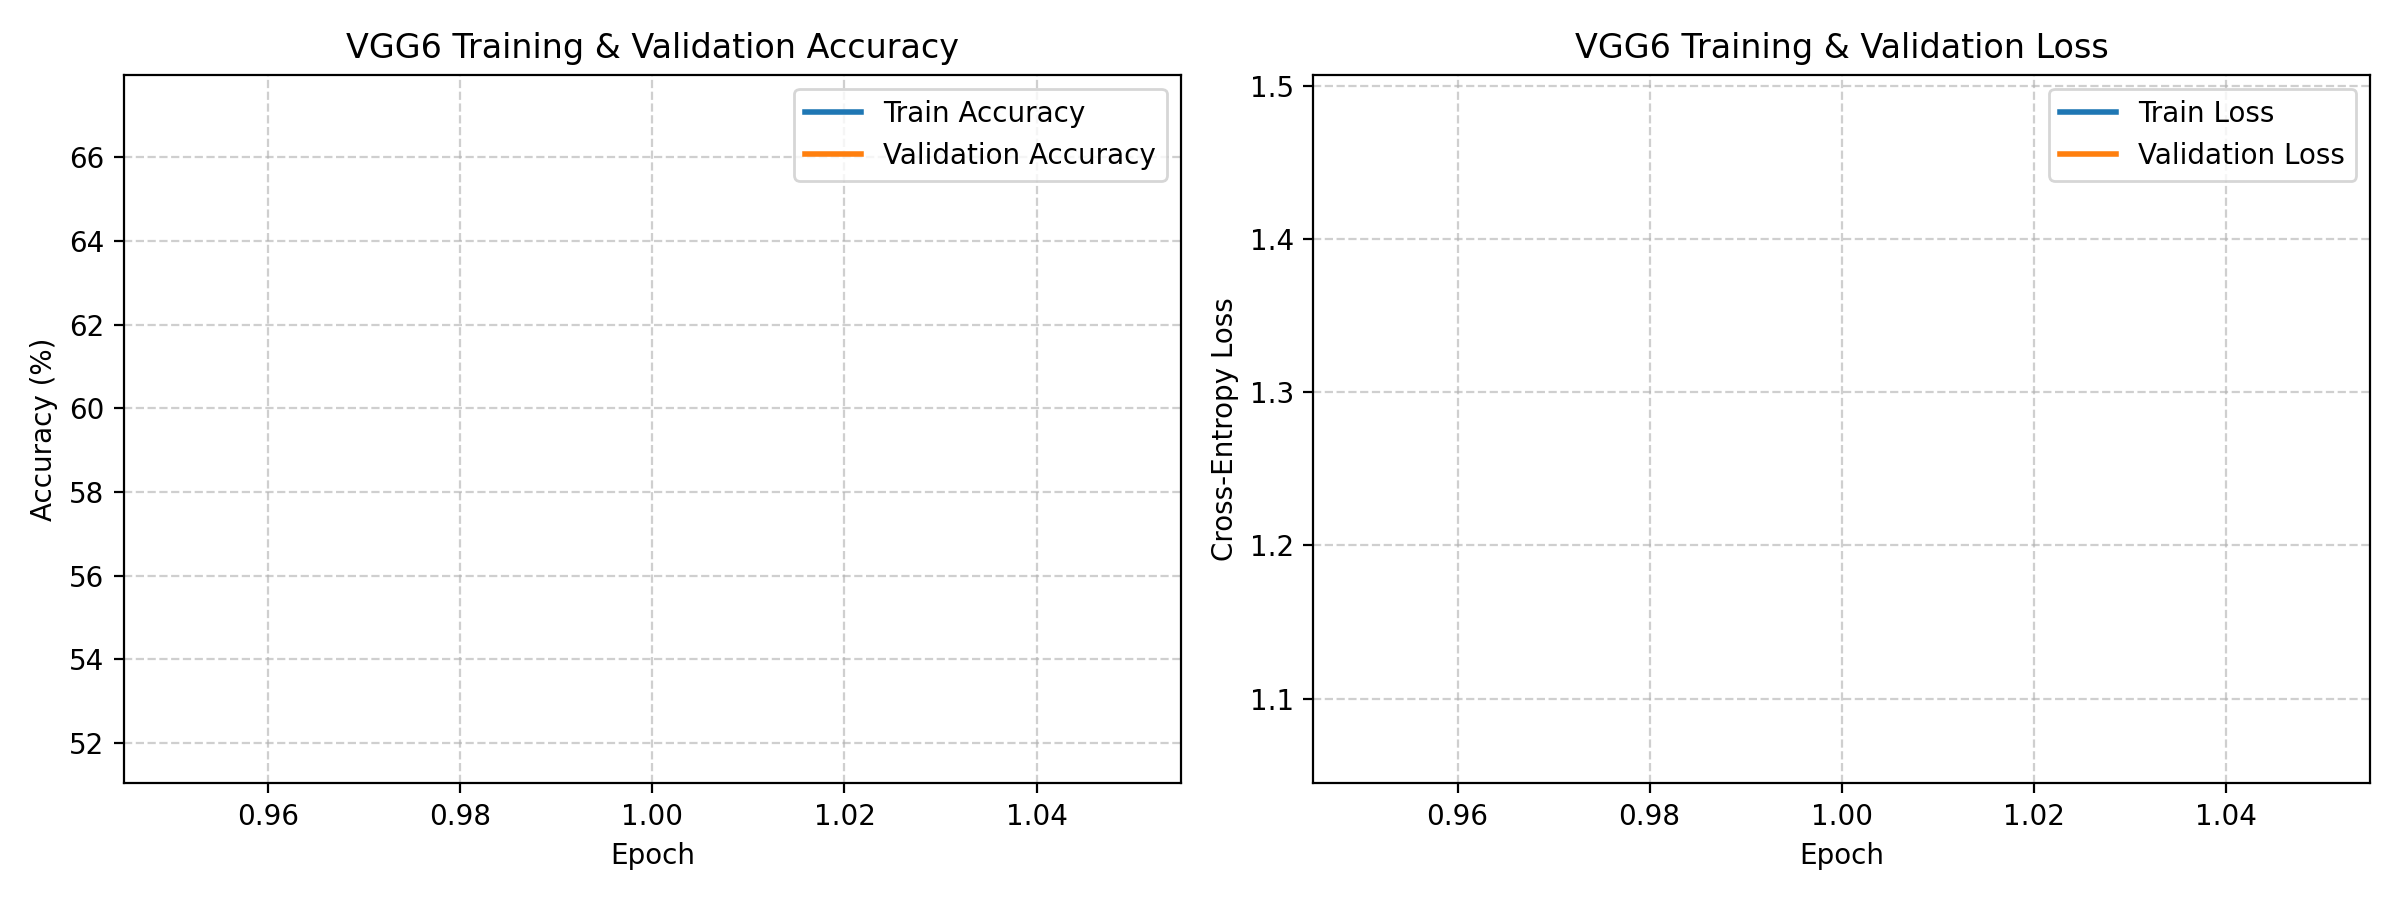

In [11]:
# ==============================================================================
# STEP 4: VISUALIZE THE SAVED LOSS & ACCURACY PLOT GENERATED BY src/train.py
# ==============================================================================
# Purpose of imports:
#   - os: Verify working directory and plot path
#   - IPython.display (Image, display): Render outputs/baseline_curves.png inline
import os
from IPython.display import Image, display

if os.path.exists("/content/iitm-cs6886w-vgg6-cifar10"):
    os.chdir("/content/iitm-cs6886w-vgg6-cifar10")

display(Image(filename="outputs/baseline_curves.png"))

In [12]:
# ==============================================================================
# STEP 5: RUN STANDALONE EVALUATION ON THE SAVED MODEL (src/evaluate.py)
# ==============================================================================
# Computes Validation Top-1 Accuracy, Test Top-1 Accuracy, and Per-Class Accuracy
import os
if os.path.exists("/content/iitm-cs6886w-vgg6-cifar10"):
    os.chdir("/content/iitm-cs6886w-vgg6-cifar10")

!python -m src.evaluate \
    --model_path checkpoints/best_vgg6_cifar10.keras \
    --batch_size 128 \
    --seed 42

I0000 00:00:1793105805.299952   79949 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793105812.839901   79949 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1793105824.801266   79949 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
Loading trained model from: checkpoints/best_vgg6_cifar10.keras
[Validation Evaluation] Loss: 1.0657 | Top-1 Accuracy: 67.20%
[Test Evaluation] Loss: 1.0563 | Top-1 Accuracy: 67.47%
E0000 00:00:1793106069.481132   79949 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_car

In [ ]:
# ==============================================================================
# STEP 6: RUN AUTOMATED W&B HYPERPARAMETER SWEEP (src/sweep.py)
# ==============================================================================
# Explores activations, optimizers, batch sizes, learning rates, epochs, and batch norm
import os
if os.path.exists("/content/iitm-cs6886w-vgg6-cifar10"):
    os.chdir("/content/iitm-cs6886w-vgg6-cifar10")

!python -m src.sweep --project cs6886w-vgg6-cifar10 --count 20

I0000 00:00:1793106121.647890   82180 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793106128.872326   82180 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
Create sweep with ID: w9ikubep
Sweep URL: https://wandb.ai/r407kumar-indian-institute-of-technology-madras/cs6886w-vgg6-cifar10/sweeps/w9ikubep
Initialized W&B Sweep ID: w9ikubep
wandb: Agent Starting Run: 0x0475cv with config:
wandb: 	activation: relu
wandb: 	batch_norm: False
wandb: 	batch_size: 128
wandb: 	dropout_rate: 0.2
wandb: 	epochs: 50
wandb: 	learning_rate: 0.005
wandb: 	momentum: 0.8
wandb: 	optimizer: sgd
wandb: 	seed: 42
wandb: 	weight_decay: 0.0005
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: r407kumar (r407kumar-indian-institute-of-technology-madras) to https://api.wandb.

In [ ]:
# ==============================================================================
# STEP 7 (QUESTION 5c): DOWNLOAD OR PUSH TRAINED MODEL TO GITHUB
# ==============================================================================
# Question 5(c) requires uploading the trained model ('checkpoints/best_vgg6_cifar10.keras')
# to your GitHub repository. Run this cell after Step 3 finishes to download the
# .keras file from Colab (then place it in 'checkpoints/' and git push to GitHub).
import os
if os.path.exists("/content/iitm-cs6886w-vgg6-cifar10"):
    os.chdir("/content/iitm-cs6886w-vgg6-cifar10")

model_file = "checkpoints/best_vgg6_cifar10.keras"
if os.path.exists(model_file):
    print(f"Trained model ready: {model_file} ({os.path.getsize(model_file) / (1024*1024):.2f} MB)")
    try:
        from google.colab import files  # Colab helper to download files to your Mac
        files.download(model_file)
    except ImportError:
        print("Running in VS Code Colab Kernel: copy checkpoints/best_vgg6_cifar10.keras or git push from Colab.")
else:
    print("Run Step 3 first to generate checkpoints/best_vgg6_cifar10.keras!")